# Module 3: Attack-Specific Mitigation and Verification (Windows Simulation)
## Comprehensive Technical Walkthrough & Verification Architecture

**Capstone Project:** Multi-Tiered IoT / Wi-Fi Intrusion Detection & Defense System  
**Dataset Benchmarks:** AWID3 (802.11 Wi-Fi) & CICIoT2023  
**Target Environment:** Safe Windows Laptop Simulation (Zero Hardware Modifications Required)  
**Future Target:** Raspberry Pi 4/5 Gateway Deployment (Hostapd & Iptables)  

---

### Three-Stage Hierarchical Defense Architecture
Module 3 operates as the terminal action tier of the multi-stage defense architecture:

```
[ Raw Network Flows / ESP32 Sensor Frames ]
                     │
                     ▼
  ┌────────────────────────────────────────────────────────┐
  │  STAGE 1: Mamdani Fuzzy Anomaly Detector (Module 1)    │
  │  - Sliding Window (W=20), IAT Dispersion (CV), Rate   │
  │  - Continuous Centroid Risk ∈ [0, 1]                   │
  └────────────────────────────────────────────────────────┘
                     │
                     │  Attack Risk ≥ 0.35 (Anomalous Traffic)
                     ▼
  ┌────────────────────────────────────────────────────────┐
  │  STAGE 2: Deep Threat Attribution & Class (Module 2)   │
  │  - Multiclass Neural Network (INT8 LSTM / Pure-NumPy RF│
  │  - Specific Threat Attribution + Confidence Score      │
  └────────────────────────────────────────────────────────┘
                     │
                     │  Prediction: Attack Category + Confidence + MAC/IP
                     ▼
  ┌──────────────────────────────────────────────────────────────────────────────┐
  │  STAGE 3: Attack-Specific Mitigation & Verification (Module 3)               │
  │                                                                              │
  │   1. Attack Info Receiver: Normalizes prediction & addressing metadata       │
  │   2. Mitigation Policy Engine: Evaluates external policies.json (13 AWID3)   │
  │   3. Simulated Network Controller: Safely simulates in-memory network state  │
  │   4. Mitigation Verifier: Evaluates % traffic reduction over equal windows   │
  │   5. Persistence & Dashboards: SQLite (mitigation_history.db) + Streamlit/UI │
  └──────────────────────────────────────────────────────────────────────────────┘
```

> **Windows Safety Notice:** All mitigation actions in this notebook are executed within an in-memory simulation controller (`SimulatedNetworkController`). No actual network adapters, firewall tables, or Windows registry configurations are modified.



## 1. Environment Setup & Library Imports
We initialize the environment, configure paths, and import all Module 3 components.


In [1]:
import sys
from pathlib import Path

# Add project root to path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Module 3 Core Imports
from module3_mitigation.models import (
    AttackEvent,
    MitigationPolicy,
    ExecutionResult,
    VerificationResult,
    MitigationRecord,
    ExecutionStatus,
    VerificationStatus,
    RemediationType,
)
from module3_mitigation.mitigation_policies import MitigationPolicyEngine
from module3_mitigation.simulated_network_controller import (
    BaseNetworkController,
    SimulatedNetworkController,
)
from module3_mitigation.traffic_simulator import TrafficSimulator
from module3_mitigation.mitigation_verifier import MitigationVerifier
from module3_mitigation.database import MitigationDatabase
from module3_mitigation.mitigation_engine import MitigationEngine
from module3_mitigation.scenarios import SCENARIOS_CATALOG, list_all_scenarios, get_scenario

print("Module 3 package imported successfully!")
print(f"Project Root: {project_root}")



Module 3 package imported successfully!
Project Root: D:\Projects\capstone


## 2. Component A: Attack Information Receiver
The receiver ingests prediction dictionaries from **Module 2** (or simulated ESP32 sensors) and normalizes them into structured `AttackEvent` dataclasses.

Supported input fields:
* `attack_type`: Categorical label (e.g., `Deauth`, `Botnet`, `SqlInjection`)
* `confidence`: Float $\in [0.0, 1.0]$ representing softmax or classifier certainty
* `source_mac`: Physical MAC address of the attacking station / sensor
* `source_ip`: Network layer IP address (if present in L3 packets)
* `destination_ip`: Target server or gateway IP
* `timestamp`: ISO-8601 UTC timestamp
* `sensor_id`: Identifier of reporting edge probe (e.g. `ESP32_01`, `GATEWAY_WIN`)



In [2]:
engine = MitigationEngine()

# Example incoming prediction from Module 2 PipelineIntegrator
m2_raw_prediction = {
    "predicted_attack": "Deauth",
    "confidence": 0.9745,
    "source_mac": "00:14:22:01:23:45",
    "source_ip": "192.168.1.185",
    "destination_ip": "192.168.1.1",
    "sensor_id": "ESP32_01"
}

# Normalize via Receiver
event = engine.parse_attack_payload(m2_raw_prediction)
print("Normalized Attack Event:")
for k, v in event.to_dict().items():
    print(f"  {k:<16}: {v}")



Normalized Attack Event:
  attack_type     : Deauth
  confidence      : 0.9745
  source_mac      : 00:14:22:01:23:45
  source_ip       : 192.168.1.185
  destination_ip  : 192.168.1.1
  timestamp       : 2026-11-04T08:05:01.426740+00:00
  sensor_id       : ESP32_01
  traffic_stats   : {}
  raw_class       : None


## 3. Component B: Attack-Specific Mitigation Policy Engine
Rather than hardcoding conditional statements, policies are defined in an external JSON configuration file (`policies.json`).

### AWID3 Dataset Policy Matrix
The policy engine covers all 13 attack categories from the **AWID3** dataset and establishes canonical aliases for **CICIoT2023** classes:

* **Automated Actions:** Executable immediately in simulation (e.g. enabling 802.11w PMF, VLAN MAC isolation, WAF query filtering, port restriction).
* **Recommended Manual Remediations:** Alerts the administrator for physical or firmware interventions (e.g. Rogue AP sweeps, WPA2 KRACK CVE-2017-13077 patches, Kr00k CVE-2019-15126 chipset updates).
* **Confidence Guard:** Low-confidence predictions ($< 	ext{threshold}$) require manual operator confirmation before enforcement.



In [3]:
policy_engine = MitigationPolicyEngine()

# Inspect all registered policies
all_policies = policy_engine.list_all_policies()
policy_rows = []
for p in all_policies:
    policy_rows.append({
        "Attack Category": p.attack_type,
        "Mitigation Action": p.mitigation_action,
        "Remediation Type": p.remediation_type.value,
        "Automated?": "Yes" if p.automated_execution else "No",
        "Admin Approval?": "Yes" if p.requires_admin_approval else "No",
        "Confidence Thresh": f"{p.confidence_threshold:.2f}",
        "Required Info": ", ".join(p.required_info) or "None",
    })

df_policies = pd.DataFrame(policy_rows)
display(df_policies)



     Attack Category  ...          Required Info
0             Deauth  ...             source_mac
1              Disas  ...             source_mac
2          (Re)Assoc  ...             source_mac
3           Rogue_AP  ...             source_mac
4              Krack  ...             source_mac
5              Kr00k  ...             source_mac
6                SSH  ...              source_ip
7             Botnet  ...             source_mac
8            Malware  ...  source_ip, source_mac
9      SQL_Injection  ...              source_ip
10              SSDP  ...              source_ip
11         Evil_Twin  ...             source_mac
12  Website_spoofing  ...         destination_ip

[13 rows x 7 columns]


Attack Category,Mitigation Action,Remediation Type,Automated?,Admin Approval?,Confidence Thresh,Required Info
Deauth,ENABLE_PMF_AND_MONITOR,AUTOMATED_ACTION,Yes,No,0.60,source_mac
Disas,ENABLE_PMF_MONITOR_DISAS,AUTOMATED_ACTION,Yes,No,0.60,source_mac
(Re)Assoc,ENFORCE_AUTH_ASSOC_POLICY,AUTOMATED_ACTION,Yes,No,0.60,source_mac
Rogue_AP,ALERT_ROGUE_AP,RECOMMENDED_MANUAL,No,Yes,0.70,source_mac
Krack,RECOMMEND_FIRMWARE_UPDATE_KRACK,RECOMMENDED_MANUAL,No,Yes,0.75,source_mac
Kr00k,RECOMMEND_FIRMWARE_UPDATE_KR00K,RECOMMENDED_MANUAL,No,Yes,0.75,source_mac
SSH,APPLY_SSH_RATE_LIMIT,AUTOMATED_ACTION,Yes,No,0.60,source_ip
Botnet,ISOLATE_INFECTED_DEVICE,AUTOMATED_ACTION,Yes,No,0.65,source_mac
Malware,QUARANTINE_ENDPOINT,AUTOMATED_ACTION,Yes,No,0.65,"source_ip, source_mac"
SQL_Injection,ACTIVATE_WAF_RULE,AUTOMATED_ACTION,Yes,No,0.60,source_ip


### Testing Confidence Threshold & Unknown Exploit Fallback
Let's see how the policy engine behaves when confidence is below threshold, or when an uncataloged zero-day attack arrives:


In [4]:
# Case 1: High-Confidence SQL Injection (Automated WAF Activation)
evt_high = AttackEvent(attack_type="SQL_Injection", confidence=0.94, source_ip="192.168.1.50")
pol_high, is_low_1, missing_1 = policy_engine.select_policy(evt_high)
print(f"High-Conf SQL Injection -> Policy: {pol_high.mitigation_action} | Low-Conf Flag: {is_low_1}")

# Case 2: Low-Confidence SQL Injection (Confidence 0.42 < 0.60 -> Requires Admin Approval)
evt_low = AttackEvent(attack_type="SQL_Injection", confidence=0.42, source_ip="192.168.1.50")
pol_low, is_low_2, missing_2 = policy_engine.select_policy(evt_low)
print(f"Low-Conf SQL Injection  -> Policy: {pol_low.mitigation_action} | Low-Conf Flag: {is_low_2} (Requires Confirmation)")

# Case 3: Novel / Uncataloged Exploit (Fallback to Administrator Alert)
evt_unknown = AttackEvent(attack_type="Unseen_Novel_Exploit_X", confidence=0.80)
pol_unk, is_low_3, missing_3 = policy_engine.select_policy(evt_unknown)
print(f"Uncataloged Attack      -> Policy: {pol_unk.mitigation_action} | Admin Approval: {pol_unk.requires_admin_approval}")



High-Conf SQL Injection -> Policy: ACTIVATE_WAF_RULE | Low-Conf Flag: False
Low-Conf SQL Injection  -> Policy: ACTIVATE_WAF_RULE | Low-Conf Flag: True (Requires Confirmation)
Uncataloged Attack      -> Policy: ALERT_ADMIN_AND_LOG | Admin Approval: True


## 4. Component C: Simulated Network Controller (Windows Laptop Safe Simulation)
The `SimulatedNetworkController` executes security actions in-memory using an adapter pattern based on `BaseNetworkController`.

Four unambiguous execution statuses are distinguished:
1. `SIMULATED_SUCCESS`: Security primitive applied successfully in simulation memory.
2. `REQUIRES_ADMIN_APPROVAL`: Action requires physical/manual remediation or confirmation.
3. `SIMULATION_FAILED`: Simulated controller failure or explicit fault override.
4. `UNSUPPORTED_ACTION`: Unrecognized exploit without automated defense.



In [5]:
controller = SimulatedNetworkController()

# 1. Simulate 802.11w PMF Activation for Deauth Attack
evt_deauth = AttackEvent(attack_type="Deauth", confidence=0.97, source_mac="00:14:22:01:23:45")
pol_deauth, _, _ = policy_engine.select_policy(evt_deauth)
res_deauth = controller.execute_mitigation(pol_deauth, evt_deauth)
print(f"Deauth Result: {res_deauth.status.value} -> {res_deauth.message}")

# 2. Simulate Device Isolation for Botnet
evt_botnet = AttackEvent(attack_type="Botnet", confidence=0.98, source_mac="E4:5F:01:AB:CD:EF")
pol_botnet, _, _ = policy_engine.select_policy(evt_botnet)
res_botnet = controller.execute_mitigation(pol_botnet, evt_botnet)
print(f"Botnet Result: {res_botnet.status.value} -> {res_botnet.message}")

# 3. Simulate SSH Throttling on Port 22
evt_ssh = AttackEvent(attack_type="SSH", confidence=0.92, source_ip="192.168.1.140")
pol_ssh, _, _ = policy_engine.select_policy(evt_ssh)
res_ssh = controller.execute_mitigation(pol_ssh, evt_ssh)
print(f"SSH Result:    {res_ssh.status.value} -> {res_ssh.message}")

# Inspect active in-memory controller state
print("\nCurrent Simulated Network Controller State:")
import pprint
pprint.pprint(controller.get_active_mitigations())



Deauth Result: SIMULATED_SUCCESS -> [SIMULATED] 802.11w Protected Management Frames (PMF) set to REQUIRED on simulated AP. Monitoring management frames from MAC 00:14:22:01:23:45.
Botnet Result: SIMULATED_SUCCESS -> [SIMULATED] Device with MAC E4:5F:01:AB:CD:EF assigned to isolated quarantine VLAN (VLAN 999). Intra-LAN forwarding dropped.
SSH Result:    SIMULATED_SUCCESS -> [SIMULATED] SSH connection rate limit applied on TCP port 22 for source IP 192.168.1.140 (3 connections / minute max).

Current Simulated Network Controller State:
{'active_waf_rules': [],
 'blocked_destinations': [],
 'isolated_macs': ['E4:5F:01:AB:CD:EF'],
 'pending_admin_alerts': 0,
 'pmf_enabled': True,
 'rate_limited_ips': {'192.168.1.140': {'limit': '3_conns_per_minute',
                                        'port': 22,
                                        'protocol': 'TCP',
                                        'timestamp': '2026-11-04T08:05:01.448391+00:00'}},
 'restricted_ports': [],
 'total_actions_

## 5. Component D: Mitigation Verification Engine
The verification engine mathematically validates whether suspicious network traffic decreased following mitigation:

$$\text{Reduction (\%)} = \left( \frac{\text{Traffic}_{\text{Before}} - \text{Traffic}_{\text{After}}}{\text{Traffic}_{\text{Before}}} \right) \times 100$$

### Decision Boundaries
* **`MITIGATION_EFFECTIVE`**: $\text{Reduction} \ge 80.0\%$
* **`PARTIALLY_EFFECTIVE`**: $30.0\% \le \text{Reduction} < 80.0\%$
* **`MITIGATION_FAILED`**: $\text{Reduction} < 30.0\%$ (or negative reduction if traffic surged)
* **`INSUFFICIENT_DATA`**: $\text{Traffic}_{\text{Before}} \le 0$ or missing telemetry



In [6]:
verifier = MitigationVerifier(effective_threshold_pct=80.0, partial_threshold_pct=30.0)

# Case 1: Highly Effective (Deauth flood: 500 -> 15 pkts/min = 97% reduction)
v1 = verifier.verify(traffic_before=500.0, traffic_after=15.0)
print(f"Case 1 (Deauth):    {v1.reduction_percentage:>5.1f}% Reduction | Status: {v1.status.value:<20}")

# Case 2: Partially Effective (SSH rate limiting: 400 -> 180 pkts/min = 55% reduction)
v2 = verifier.verify(traffic_before=400.0, traffic_after=180.0)
print(f"Case 2 (SSH):       {v2.reduction_percentage:>5.1f}% Reduction | Status: {v2.status.value:<20}")

# Case 3: Failed Mitigation (SSDP bypass: 1000 -> 950 pkts/min = 5% reduction)
v3 = verifier.verify(traffic_before=1000.0, traffic_after=950.0)
print(f"Case 3 (SSDP Fail): {v3.reduction_percentage:>5.1f}% Reduction | Status: {v3.status.value:<20}")

# Case 4: Zero Baseline Traffic Edge Case
v4 = verifier.verify(traffic_before=0.0, traffic_after=0.0)
print(f"Case 4 (Zero Base): {v4.reduction_percentage:>5.1f}% Reduction | Status: {v4.status.value:<20}")



Case 1 (Deauth):     97.0% Reduction | Status: MITIGATION_EFFECTIVE
Case 2 (SSH):        55.0% Reduction | Status: PARTIALLY_EFFECTIVE 
Case 3 (SSDP Fail):   5.0% Reduction | Status: MITIGATION_FAILED   
Case 4 (Zero Base):   0.0% Reduction | Status: INSUFFICIENT_DATA   


### Visualizing Dynamic Verification Timeline
The timeline plot below illustrates pre-mitigation telemetry (~500 pkts/min), the exact PMF enforcement trigger, and post-mitigation stabilization (~15 pkts/min) over consecutive 60-second observation windows:


<IPython.core.display.Image object>


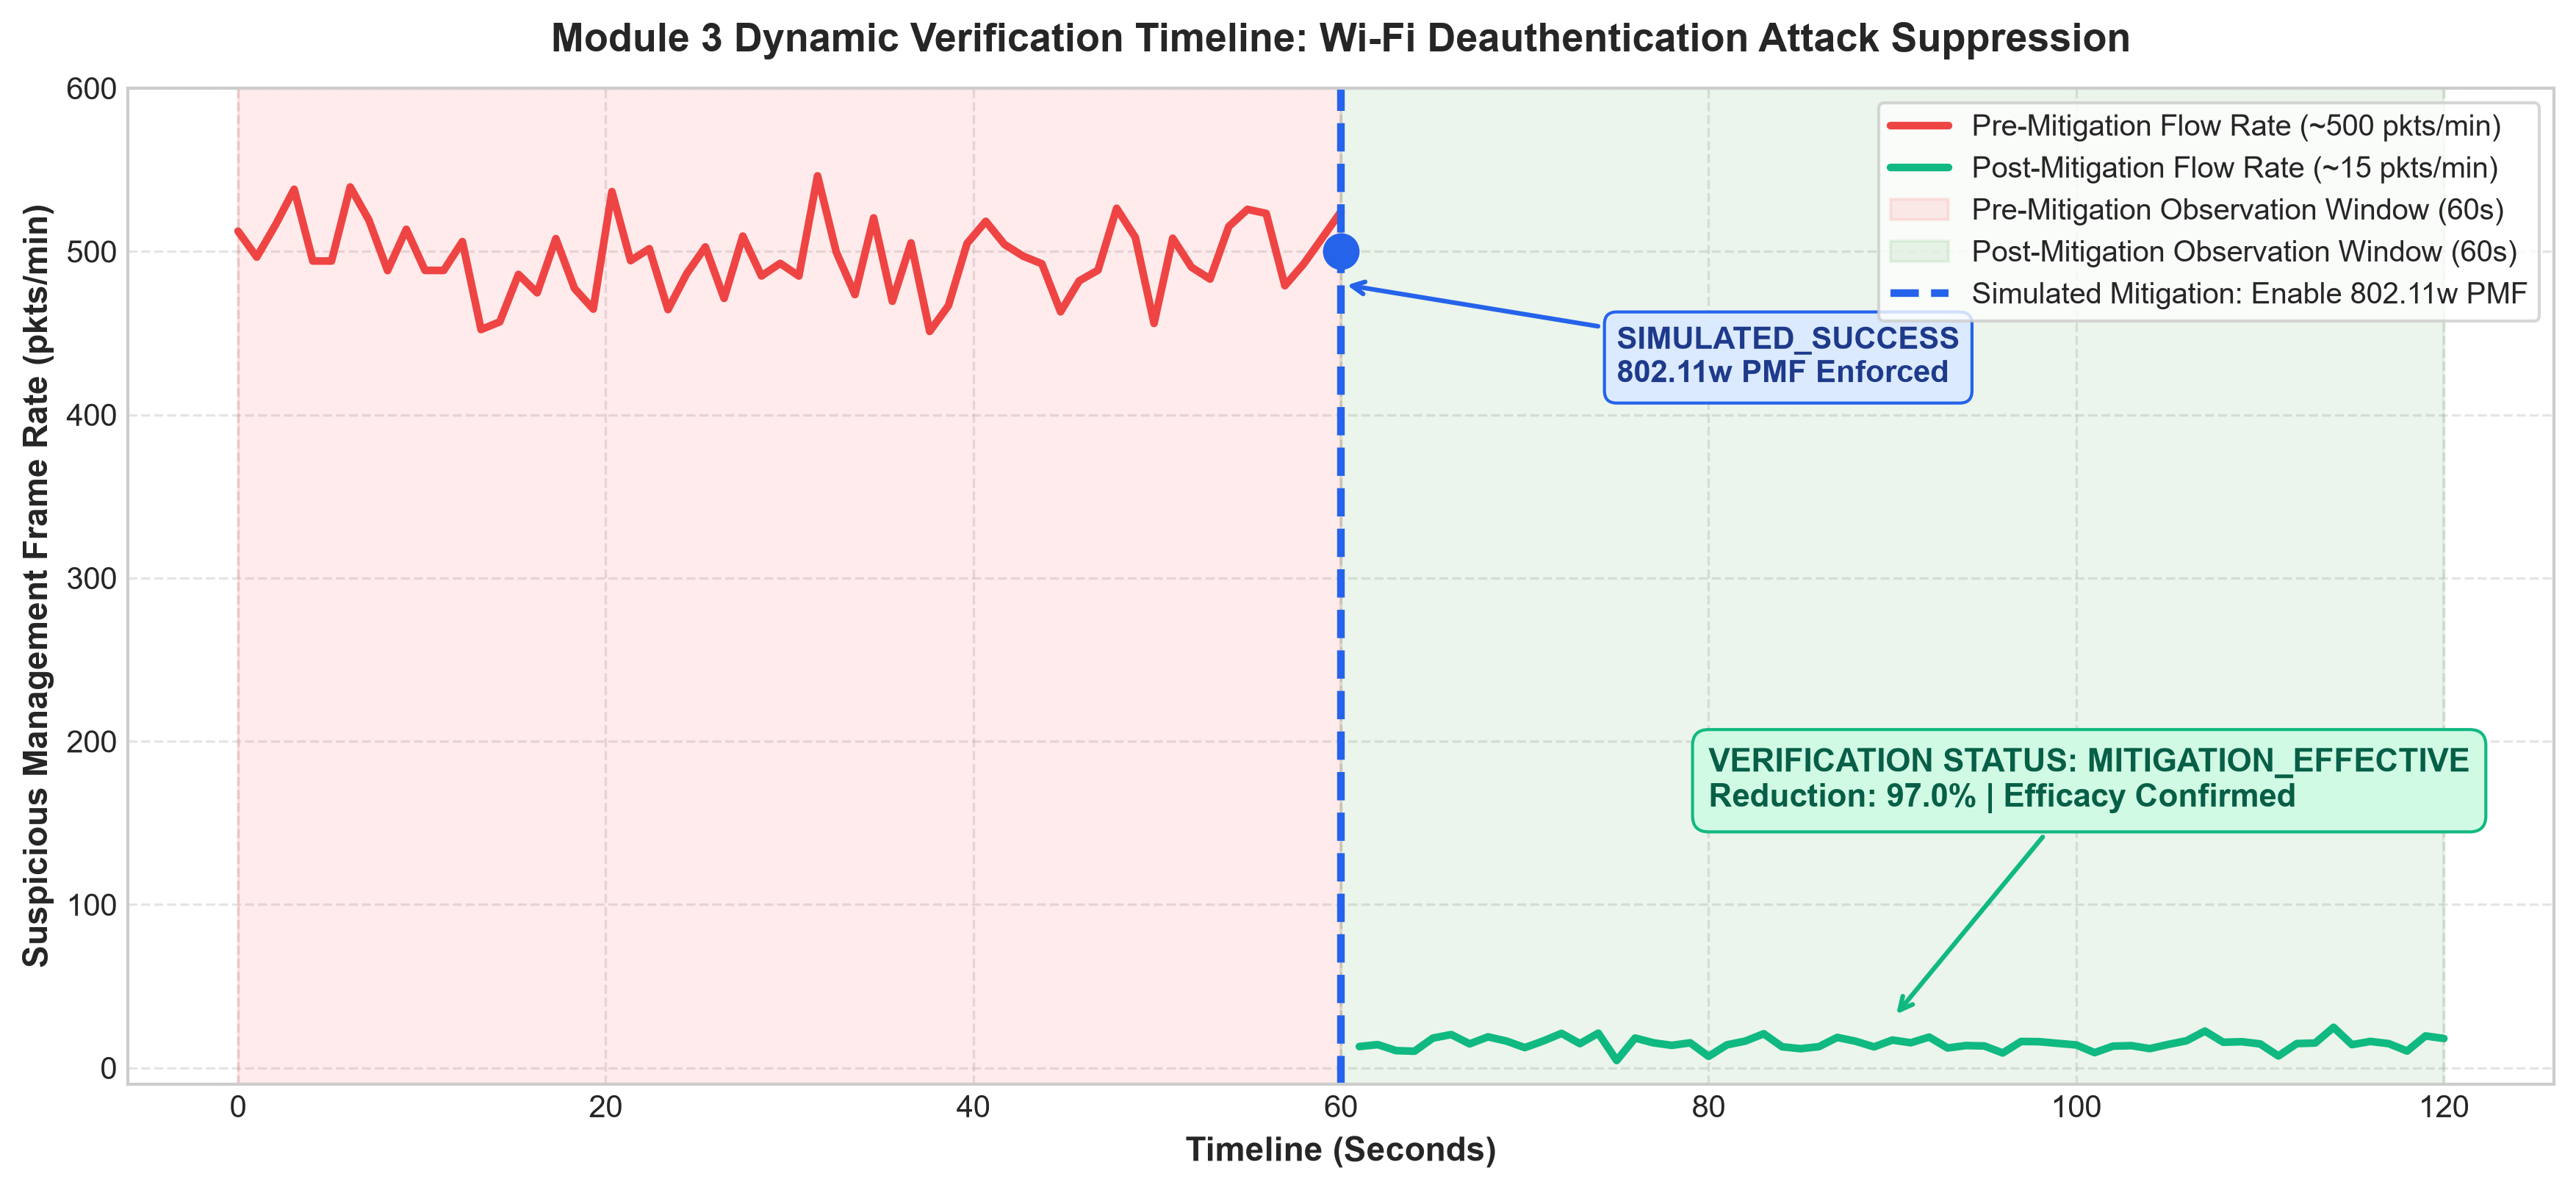

In [7]:
timeline_plot_path = project_root / "results" / "plots" / "module3_verification_timeline.png"
if timeline_plot_path.exists():
    display(Image(str(timeline_plot_path)))
else:
    print(f"Plot not found at {timeline_plot_path}")



## 6. Comprehensive Walkthrough: The 8 Simulation Scenarios
Module 3 includes a benchmark test suite of 8 reproducible scenarios that evaluate all combinations of policy actions, execution outcomes, and verification statuses:

1. **Deauth Attack:** PMF enabled on AP $\to$ 97% reduction $\to$ `MITIGATION_EFFECTIVE`
2. **Botnet Attack:** Infected MAC isolated to VLAN 999 $\to$ 100% reduction $\to$ `MITIGATION_EFFECTIVE`
3. **SSH Brute-Force:** Port 22 rate limited $\to$ 55% reduction $\to$ `PARTIALLY_EFFECTIVE`
4. **Rogue AP:** Manual sweep alert $\to$ Requires Admin Approval $\to$ `MITIGATION_FAILED` (0% auto drop)
5. **Malware C2:** Endpoint quarantined $\to$ 97.5% reduction $\to$ `MITIGATION_EFFECTIVE`
6. **Unknown Attack:** Uncataloged exploit $\to$ Fallback logged $\to$ `UNSUPPORTED_ACTION`
7. **Low-Confidence Alert:** Softmax certainty (0.42 < 0.60) $\to$ Requires Admin Confirmation
8. **Failed Mitigation:** Throttling fails to stem assault (5% drop) $\to$ `MITIGATION_FAILED`



In [8]:
scenario_results = []

for sc_id in range(1, 9):
    rec = engine.run_scenario(sc_id)
    scenario_results.append({
        "Scenario #": sc_id,
        "Attack Category": rec.attack_type,
        "Confidence": f"{rec.confidence*100:.1f}%",
        "Action Selected": rec.mitigation_action,
        "Execution Status": rec.execution_status.value,
        "Traffic (Before)": f"{rec.traffic_before:.0f} pkts/min",
        "Traffic (After)": f"{rec.traffic_after:.0f} pkts/min",
        "Reduction": f"{rec.reduction_percentage:.1f}%",
        "Verification Status": rec.verification_status.value,
    })

df_scenarios = pd.DataFrame(scenario_results)
display(df_scenarios)



   Scenario #          Attack Category  ... Reduction   Verification Status
0           1                   Deauth  ...     97.0%  MITIGATION_EFFECTIVE
1           2                   Botnet  ...    100.0%  MITIGATION_EFFECTIVE
2           3                      SSH  ...     55.0%   PARTIALLY_EFFECTIVE
3           4                 Rogue_AP  ...      0.0%     MITIGATION_FAILED
4           5                  Malware  ...     97.5%  MITIGATION_EFFECTIVE
5           6  Unknown_Novel_Exploit_X  ...      0.0%     MITIGATION_FAILED
6           7            SQL_Injection  ...      0.0%     MITIGATION_FAILED
7           8                     SSDP  ...      5.0%     MITIGATION_FAILED

[8 rows x 9 columns]


Scenario #,Attack Category,Confidence,Action Selected,Execution Status,Traffic (Before),Traffic (After),Reduction,Verification Status
1,Deauth,97.0%,ENABLE_PMF_AND_MONITOR,SIMULATED_SUCCESS,500 pkts/min,15 pkts/min,97.0%,MITIGATION_EFFECTIVE
2,Botnet,98.0%,ISOLATE_INFECTED_DEVICE,SIMULATED_SUCCESS,1200 pkts/min,0 pkts/min,100.0%,MITIGATION_EFFECTIVE
3,SSH,92.0%,APPLY_SSH_RATE_LIMIT,SIMULATED_SUCCESS,400 pkts/min,180 pkts/min,55.0%,PARTIALLY_EFFECTIVE
4,Rogue_AP,94.0%,ALERT_ROGUE_AP,REQUIRES_ADMIN_APPROVAL,180 pkts/min,180 pkts/min,0.0%,MITIGATION_FAILED
5,Malware,95.0%,QUARANTINE_ENDPOINT,SIMULATED_SUCCESS,800 pkts/min,20 pkts/min,97.5%,MITIGATION_EFFECTIVE
6,Unknown_Novel_Exploit_X,70.0%,ALERT_ADMIN_AND_LOG,UNSUPPORTED_ACTION,300 pkts/min,300 pkts/min,0.0%,MITIGATION_FAILED
7,SQL_Injection,42.0%,ACTIVATE_WAF_RULE,REQUIRES_ADMIN_APPROVAL,350 pkts/min,350 pkts/min,0.0%,MITIGATION_FAILED
8,SSDP,88.0%,RESTRICT_UDP_PORT_1900,SIMULATED_SUCCESS,1000 pkts/min,950 pkts/min,5.0%,MITIGATION_FAILED


### Visualizing Traffic Telemetry across all 8 Scenarios:


<IPython.core.display.Image object>


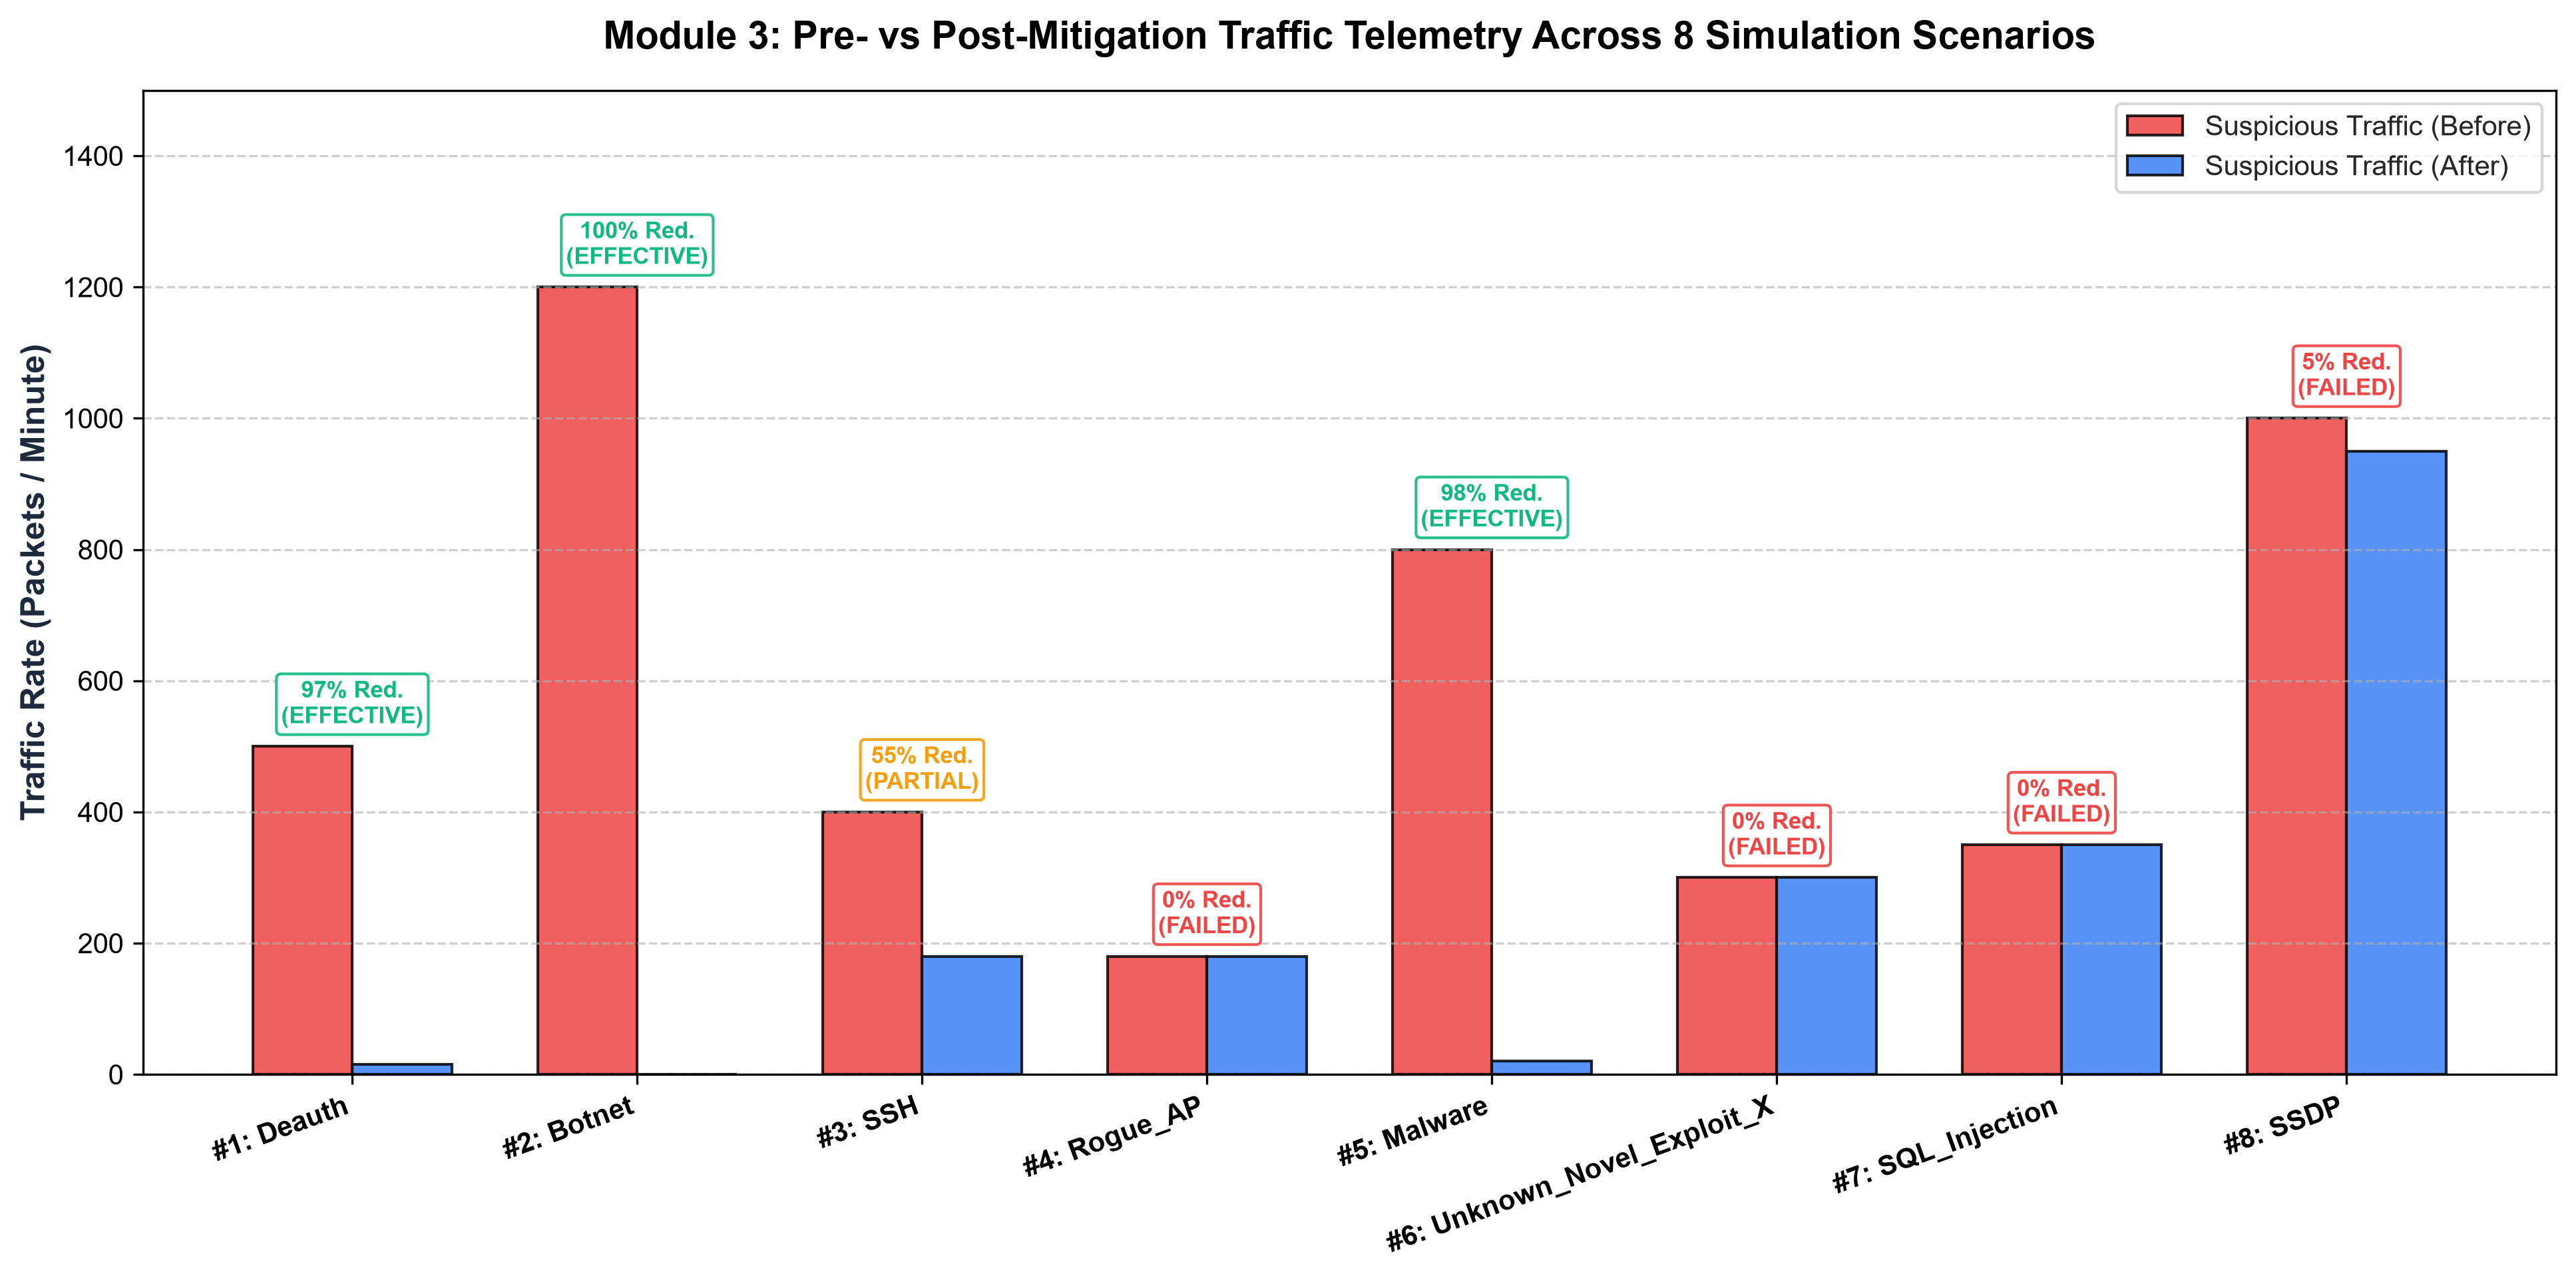

In [9]:
bar_plot_path = project_root / "results" / "plots" / "module3_traffic_reduction_scenarios.png"
if bar_plot_path.exists():
    display(Image(str(bar_plot_path)))
else:
    print(f"Plot not found at {bar_plot_path}")



## 7. Component E: SQLite Database Persistence & Logging
All mitigation events, execution statuses, and mathematical verification results are saved to a local SQLite database: `data/mitigation_history.db`.
Audit logs are written simultaneously to `results/mitigation.log`.



In [10]:
db = engine.database

# Summary statistics from SQLite
stats = db.get_summary_stats()
print("SQLite Aggregated Statistics:")
for k, v in stats.items():
    print(f"  {k:<20}: {v}")

# Query recent records
recent_records = db.get_recent_records(limit=5)
df_recent = pd.DataFrame(recent_records)[["id", "timestamp", "attack_type", "confidence", "mitigation_action", "execution_status", "reduction_percentage", "verification_status"]]
display(df_recent)



SQLite Aggregated Statistics:
  total_events        : 13
  effective_count     : 5
  partial_count       : 3
  failed_count        : 5
  approval_count      : 4
  avg_reduction_pct   : 52.42
   id  ...   verification_status
0  15  ...     MITIGATION_FAILED
1  14  ...     MITIGATION_FAILED
2  13  ...     MITIGATION_FAILED
3  12  ...  MITIGATION_EFFECTIVE
4  11  ...     MITIGATION_FAILED

[5 rows x 8 columns]


## 8. End-to-End Integration: Module 1 → Module 2 → Module 3
We test the complete pipeline handoff from an anomalous window detection to mitigation verification:



In [11]:
# Simulated output from PipelineIntegrator (Module 1 alert -> Module 2 classification)
pipeline_output = {
    "window_id": 108,
    "module1_verdict": "ATTACK",
    "attack_risk": 0.942,
    "module2_invoked": True,
    "predicted_attack": "DDoS-UDP_Flood",  # Classified by Module 2 (maps to Botnet policy)
    "raw_class": "DDoS-UDP_Flood",
    "class_id": 14,
    "confidence": 0.9821,
    "is_zero_day": False,
    "module2_runtime": "INT8_TFLite",
    "module2_inference_latency_ms": 0.087,
    "total_pipeline_latency_ms": 1.150,
}

# Module 3 processes pipeline prediction
mitigation_result = engine.mitigate_from_pipeline(
    pipeline_output=pipeline_output,
    source_mac="E4:5F:01:FE:DC:BA",
    source_ip="192.168.1.185",
    sensor_id="ESP32_01",
)

print("Pipeline Integration Successful!")
print(f"Attack Identified:    {mitigation_result.attack_type}")
print(f"Action Executed:      {mitigation_result.mitigation_action}")
print(f"Controller Status:    {mitigation_result.execution_status.value}")
print(f"Traffic Reduction:    {mitigation_result.reduction_percentage}% ({mitigation_result.traffic_before} -> {mitigation_result.traffic_after} pkts/min)")
print(f"Verification Result:  {mitigation_result.verification_status.value}")
print(f"Persisted Record ID:  #{mitigation_result.id}")



Pipeline Integration Successful!
Attack Identified:    DDoS-UDP_Flood
Action Executed:      ISOLATE_INFECTED_DEVICE
Controller Status:    SIMULATED_SUCCESS
Traffic Reduction:    100.0% (1200.0 -> 0.0 pkts/min)
Verification Result:  MITIGATION_EFFECTIVE
Persisted Record ID:  #16


## 9. Web Dashboards & Visual Verification
Module 3 provides two synchronized dashboard interfaces:
1. **Integrated Streamlit Dashboard (`app.py` - Tab 2):** Integrated alongside Module 1 and 2 feature sliders, fuzzy curves, and model comparison tabs.
2. **Dedicated Flask Web Dashboard & REST API (`web/app.py`):** Standalone dashboard with live JSON REST endpoints (`/api/mitigate`, `/api/scenarios`, `/api/history`).

### Module 3 Interactive Dashboard View:



<IPython.core.display.Image object>


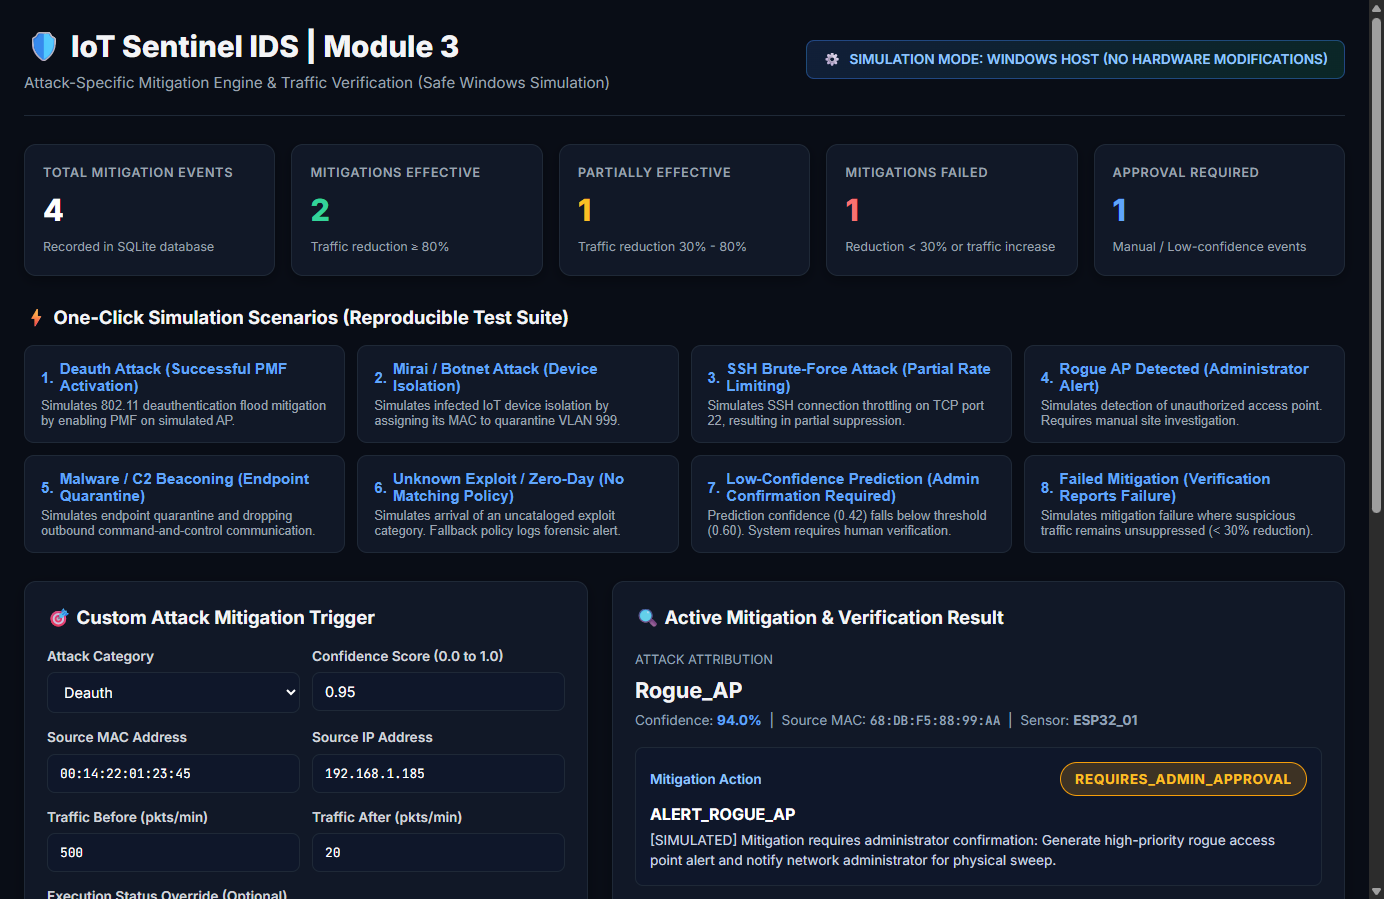

In [12]:
dash_img_path = project_root / "results" / "plots" / "module3_dashboard_view.png"
if dash_img_path.exists():
    display(Image(str(dash_img_path)))
else:
    print(f"Screenshot not found at {dash_img_path}")



## 10. Raspberry Pi Deployment & Physical Network Migration
Because `SimulatedNetworkController` implements the `BaseNetworkController` abstract adapter, transitioning from Windows simulation to a physical Raspberry Pi gateway requires zero alterations to the Policy Engine or Verifier:

```
                   Current Windows Simulation
                   ┌────────────────────────┐
                   │ SimulatedNetworkCtrl   │ (In-Memory State)
                   └────────────────────────┘
                               │
               Replace via Adapter Pattern with:
                               │
                               ▼
                   Physical Raspberry Pi Gateway
                   ┌────────────────────────┐
                   │ LinuxNetworkController │
                   └───────────┬────────────┘
                               │
        ┌──────────────────────┼──────────────────────┐
        ▼                      ▼                      ▼
  hostapd_cli / iw          iptables / nftables    tc (traffic control)
  (Enforce 802.11w PMF,     (Isolate MACs, Drop    (Token Bucket Filter
   AP station deauth)        outbound C2, WAF)      rate limiting port 22)
```

### Physical Gateway Linux Implementation Mapping:
1. **Deauth / PMF Enforcement:**
   ```bash
   hostapd_cli set ieee80211w 2
   hostapd_cli disassociate <ATTACKER_MAC>
   ```
2. **Botnet / Infected Device Isolation:**
   ```bash
   iptables -I FORWARD -m mac --mac-source <MAC> -j DROP
   ebtables -A FORWARD -s <MAC> -j DROP
   ```
3. **SSH Rate Limiting (Port 22):**
   ```bash
   iptables -I INPUT -p tcp --dport 22 -m state --state NEW -m recent --set
   iptables -I INPUT -p tcp --dport 22 -m state --state NEW -m recent --update --seconds 60 --hitcount 4 -j DROP
   ```
4. **Live Traffic Observation:**
   Replace `TrafficSimulator` with real-time packet counters querying Linux `/sys/class/net/<wlan0>/statistics/rx_packets` or `libpcap` before and after mitigation over equal 60-second observation intervals.

